<a href="https://colab.research.google.com/github/angelatodorovic/USD-JPY-zero-shot-sentiment-analysis/blob/main/USDJPY_zero_shot_scoring.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# USD/JPY zero-shot scoring, one article at a time with Anthropic Claude Opus 4.6

*This is a sample notebook made for the Macroeconomics project at International University of Monaco. See below details on the reproducibility, which would require you to purchase usage credits for Claude*

Each article is sent to the model on its own, in a fresh API call, with the same prompt, at temperature 0. No article ever sees another.

**Reproducibility with own API key**
1. Get an API key: Anthropic at console.anthropic.com.
2. In Colab, click the key icon on the left, add a secret named `ANTHROPIC_API_KEY`, paste the key, and switch on notebook access.
3. Set PROVIDER and MODEL in section 2, then Runtime > Run all and upload `USDJPY_Sentiment_Model_filled.xlsx` when asked.

Every answer is saved as it arrives, so if the run stops, run section 6 again and it continues as normal.

## 1. Install

In [1]:
!pip install -q openai anthropic beautifulsoup4 openpyxl

## 2. Settings

In [2]:
PROVIDER = "anthropic"        # "anthropic" (Claude) or "openai" (ChatGPT)
MODEL = "claude-haiku-4-5-20251001"   # oldest Claude still available: reliable knowledge to Feb 2025,
                              # training data to Jul 2025 (see section 9 for the look-ahead check)
                              # ChatGPT alternative: PROVIDER = "openai", MODEL = "gpt-4o-mini"
TRAINING_CUTOFF = "2025-07-31"  # end of the model's training data; articles after it are clean
RUNS = 3                      # independent calls per article and prompt (agreement between them = reliability)
TEMPERATURE = 0.0
USE_FULL_TEXT = True          # add the article text from its web link (headline only if the page cannot be read)
ARTICLE_WORDS = 400           # how much of the article to send
SCORE_FORWARD = False         # set True to also run the -2..+2 next-week prompt

## 3. Prompts and functions

In [3]:
import re, time, json, random, statistics
from pathlib import Path
from collections import Counter
import pandas as pd
import requests

UA = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124 Safari/537.36"}

PROMPT_TONE = (
    "Clear all prior contexts and instructions. As a finance expert, evaluate the potential effect of the following "
    "economic commentary on the USD/JPY exchange rate in the short term. Using only the information in the commentary, "
    "predict whether the impact will be an increase (UP), a decrease (DOWN), or uncertain (UNCERTAIN). An increase means "
    "the US dollar strengthens against the Japanese yen; a decrease means the Japanese yen strengthens against the US dollar. "
    "Choose only one option, UP, DOWN, or UNCERTAIN, and refrain from providing further comments.\nCommentary: {text}"
)
PROMPT_FWD = (
    "Clear all prior contexts and instructions. You are a foreign-exchange strategist. Read the FX market commentary "
    "below. Using only this information, assess its implication for the USD/JPY exchange rate over the next week, where "
    "an increase means the US dollar strengthens against the Japanese yen. Choose one score: -2 (strong decrease), "
    "-1 (moderate decrease), 0 (no clear direction or uncertain), +1 (moderate increase), +2 (strong increase). "
    "Reply with the score only.\nCommentary: {text}"
)

HL_RE = re.compile(r'^=HYPERLINK\(\s*"((?:[^"]|"")*)"\s*,\s*"((?:[^"]|"")*)"\s*\)\s*$', re.I)


def read_headlines(model_path, first_row=2, last_row=20001):
    from openpyxl import load_workbook
    ws = load_workbook(model_path)["Headlines"]
    rows = []
    for r in range(first_row, last_row + 1):
        c = ws.cell(row=r, column=3).value
        if c in (None, ""):
            continue
        c = str(c); url = ""
        m = HL_RE.match(c)
        if m:
            url, text = m.group(1).replace('""', '"'), m.group(2).replace('""', '"')
        else:
            text = c
        src = str(ws.cell(row=r, column=2).value or "")
        if not url:
            u = re.search(r"https?://\S+", src)
            url = u.group(0) if u else ""
        rows.append({"row": r, "date": ws.cell(row=r, column=1).value, "source": src.split(",")[0].strip(),
                     "headline": text.strip(), "url": url})
    return pd.DataFrame(rows)


def fetch_lead(url, max_words=120):
    """First substantive paragraph(s) of the article, or '' if unavailable."""
    if not url:
        return ""
    try:
        from bs4 import BeautifulSoup
        r = requests.get(url, headers=UA, timeout=20)
        if r.status_code != 200:
            return ""
        soup = BeautifulSoup(r.text, "html.parser")
        for t in soup(["script", "style", "nav", "header", "footer", "aside", "form"]):
            t.decompose()
        bad = re.compile(r"cookie|subscribe|sign up|disclaimer|privacy|javascript|newsletter|all rights", re.I)
        words = []
        for p in soup.find_all("p"):
            s = " ".join(p.get_text(" ", strip=True).split())
            if len(s.split()) < 20 or bad.search(s):
                continue
            words += s.split()
            if len(words) >= max_words:
                break
        return " ".join(words[:max_words])
    except Exception:
        return ""


def build_text(headline, lead):
    return headline if not lead else f"{headline}. {lead}"


def parse_tone(s):
    s = (s or "").upper()
    for k in ("UNCERTAIN", "DOWN", "UP"):
        if re.search(rf"\b{k}\b", s):
            return k
    return None


def parse_fwd(s):
    s = (s or "").replace("−", "-").replace("–", "-")
    m = re.search(r"([+-]?)\s*([0-2])(?![0-9.])", s)
    if not m:
        return None
    v = int(m.group(2))
    return -v if m.group(1) == "-" else v


def make_caller(provider, model, api_key, temperature=0.0, max_tokens=10):
    """Returns call(prompt) -> text. Falls back to settings that reasoning-style models accept."""
    provider = provider.lower()
    if provider == "openai":
        from openai import OpenAI
        cl = OpenAI(api_key=api_key)
        def call(p):
            msg = [{"role": "user", "content": p}]
            try:
                r = cl.chat.completions.create(model=model, messages=msg, temperature=temperature, max_tokens=max_tokens)
            except Exception as e:      # newer reasoning models reject temperature / max_tokens
                if "temperature" not in str(e) and "max_tokens" not in str(e):
                    raise
                r = cl.chat.completions.create(model=model, messages=msg, max_completion_tokens=max(500, max_tokens))
            return r.choices[0].message.content
    elif provider == "anthropic":
        import anthropic
        cl = anthropic.Anthropic(api_key=api_key)
        def call(p):
            r = cl.messages.create(model=model, max_tokens=max_tokens, temperature=temperature,
                                   messages=[{"role": "user", "content": p}])
            return "".join(getattr(b, "text", "") for b in r.content)
    elif provider == "gemini":
        from google import genai
        cl = genai.Client(api_key=api_key)
        def call(p):
            cfg = {"temperature": temperature, "max_output_tokens": max(50, max_tokens), "thinking_config": {"thinking_budget": 0}}
            try:
                r = cl.models.generate_content(model=model, contents=p, config=cfg)
            except Exception as e:      # models without a thinking setting
                if "thinking" not in str(e).lower():
                    raise
                cfg.pop("thinking_config"); cfg["max_output_tokens"] = 500
                r = cl.models.generate_content(model=model, contents=p, config=cfg)
            return r.text or ""
    else:
        raise ValueError("provider must be openai, anthropic or gemini")
    return call


def score_all(df, call, runs, log_path, pause=0.3, model_name=""):
    """Each headline x prompt x run is a separate, fresh API call. Resumable via the log CSV."""
    log_path = Path(log_path)
    done = set()
    if log_path.exists():
        old = pd.read_csv(log_path)
        done = set(zip(old["row"], old["prompt"], old["run"]))
    todo = [(r.row, p, k, r.text) for r in df.itertuples() for p in ("tone", "fwd") for k in range(1, runs + 1)
            if (r.row, p, k) not in done]
    print(f"{len(todo)} calls to make ({len(done)} already in the log).")
    for n, (row, p, k, text) in enumerate(todo, 1):
        prompt = (PROMPT_TONE if p == "tone" else PROMPT_FWD).format(text=text)
        raw = None
        for attempt in range(4):
            try:
                raw = call(prompt); break
            except Exception as e:
                wait = 5 * (attempt + 1)
                print(f"   API error ({e}); retry in {wait}s"); time.sleep(wait)
        parsed = parse_tone(raw) if p == "tone" else parse_fwd(raw)
        pd.DataFrame([{"model": model_name, "row": row, "prompt": p, "run": k, "raw": raw, "parsed": parsed}]).to_csv(
            log_path, mode="a", header=not log_path.exists(), index=False)
        if n % 25 == 0 or n == len(todo):
            print(f"  {n}/{len(todo)}")
        time.sleep(pause)
    return pd.read_csv(log_path)


def aggregate(log):
    out = []
    for row, g in log.groupby("row"):
        tone = [x for x in g[g.prompt == "tone"].parsed if isinstance(x, str)]
        fwd = [float(x) for x in g[g.prompt == "fwd"].parsed if pd.notna(x)]
        rec = {"row": row}
        if tone:
            c = Counter(tone).most_common()
            top = c[0][0] if (len(c) == 1 or c[0][1] > c[1][1]) else "UNCERTAIN"   # tie -> UNCERTAIN
            rec.update(tone=top, tone_agree=c[0][1] / len(tone))
        if fwd:
            mode_n = Counter(fwd).most_common(1)[0][1]
            rec.update(fwd=round(statistics.mean(fwd), 4), fwd_agree=mode_n / len(fwd))
        out.append(rec)
    return pd.DataFrame(out)


def consensus_tone(labels):
    labels = [x for x in labels if isinstance(x, str)]
    if not labels:
        return None, None
    c = Counter(labels).most_common()
    top = c[0][0] if (len(c) == 1 or c[0][1] > c[1][1]) else "UNCERTAIN"
    return top, sum(1 for x in labels if x == top) / len(labels)


def write_back_multi(model_in, aggs, model_names, model_out):
    """aggs: list of per-LLM aggregate tables (same order as model_names, max 3)."""
    from openpyxl import load_workbook
    wb = load_workbook(model_in)
    ws = wb["Headlines"]
    if str(ws["O1"].value or "") != "Tone_M1":
        raise ValueError("This model has no per-LLM columns. Use USDJPY_Sentiment_Model_filled_7.xlsx or later.")
    tone_cols, fwd_cols = (15, 17, 19), (16, 18, 20)
    rows = sorted(set().union(*[set(a.row) for a in aggs]))
    for r in range(2, 20002):                      # clear old per-LLM answers
        for c in tone_cols + fwd_cols:
            ws.cell(row=r, column=c).value = None
    for m in range(3):
        wb["Inputs"].cell(row=51 + m, column=2).value = model_names[m] if m < len(model_names) else None
    for r in rows:
        tones, fwds = [], []
        for m, a in enumerate(aggs[:3]):
            hit = a[a.row == r]
            if hit.empty:
                continue
            t, f = hit.iloc[0].get("tone"), hit.iloc[0].get("fwd")
            if isinstance(t, str):
                ws.cell(row=r, column=tone_cols[m], value=t); tones.append(t)
            if pd.notna(f):
                ws.cell(row=r, column=fwd_cols[m], value=float(f)); fwds.append(float(f))
        top, agree = consensus_tone(tones)
        if top:
            ws.cell(row=r, column=6, value=top)
            ws.cell(row=r, column=12, value=agree)
        if fwds:
            ws.cell(row=r, column=11, value=round(sum(fwds) / len(fwds), 4))
    wb.calculation.fullCalcOnLoad = True
    wb.save(model_out)
    print(f"Wrote scores from {len(aggs)} LLM(s) for {len(rows)} headlines into {model_out}")

print('TONE PROMPT:'); print(PROMPT_TONE.format(text='<article>'))
if SCORE_FORWARD:
    print('\nFORWARD PROMPT:'); print(PROMPT_FWD.format(text='<article>'))

TONE PROMPT:
Clear all prior contexts and instructions. As a finance expert, evaluate the potential effect of the following economic commentary on the USD/JPY exchange rate in the short term. Using only the information in the commentary, predict whether the impact will be an increase (UP), a decrease (DOWN), or uncertain (UNCERTAIN). An increase means the US dollar strengthens against the Japanese yen; a decrease means the Japanese yen strengthens against the US dollar. Choose only one option, UP, DOWN, or UNCERTAIN, and refrain from providing further comments.
Commentary: <article>


In [6]:
def make_caller(provider, model, api_key, temperature=0.0, max_tokens=10):
    if provider.lower() != "anthropic":
        raise ValueError("this fix only covers anthropic")
    import anthropic
    cl = anthropic.Anthropic(api_key=api_key)
    msg = lambda p: [{"role": "user", "content": p}]
    def call(p):
        try:      # newer SDK: pass temperature in the request body
            r = cl.messages.create(model=model, max_tokens=max_tokens, messages=msg(p),
                                   extra_body={"temperature": temperature})
        except Exception as e:
            if "temperature" not in str(e):
                raise
            print("Note: this model does not accept a temperature setting; using its default.")
            r = cl.messages.create(model=model, max_tokens=max_tokens, messages=msg(p))
        return "".join(getattr(b, "text", "") for b in r.content)
    return call

## 4. API key and model

In [17]:
import requests
from google.colab import userdata
API_KEY = userdata.get('ANTHROPIC_API_KEY')

# --- prompt (Ma, Lyu & Li adapted to USD/JPY, plus one sentence on the quote convention) ---
PROMPT_TONE = (
    "Clear all prior contexts and instructions. As a finance expert, evaluate the potential effect of the following "
    "economic commentary on the USD/JPY exchange rate in the short term. Using only the information in the commentary, "
    "predict whether the impact will be an increase (UP), a decrease (DOWN), or uncertain (UNCERTAIN). An increase means "
    "the US dollar strengthens against the Japanese yen; a decrease means the Japanese yen strengthens against the US dollar. "
    "USD/JPY is quoted in yen per US dollar, so news that weakens the yen means UP and news that strengthens the yen means DOWN. "
    "Choose only one option, UP, DOWN, or UNCERTAIN, and refrain from providing further comments.\nCommentary: {text}"
)

def parse_tone(s):
    s = (s or "").upper()
    for k in ("UNCERTAIN", "DOWN", "UP"):
        if k in s:
            return k
    return None

# --- one fresh API call per prompt, temperature 0 (older API version that still accepts it) ---
def make_call(model):
    def call(p, max_tokens=10):
        r = requests.post(
            "https://api.anthropic.com/v1/messages",
            headers={"x-api-key": API_KEY, "anthropic-version": "2023-06-01", "content-type": "application/json"},
            json={"model": model, "max_tokens": max_tokens, "temperature": 0,
                  "messages": [{"role": "user", "content": p}]},
            timeout=60)
        if r.status_code != 200:
            raise RuntimeError(f"{r.status_code}: {r.text[:200]}")
        return "".join(b.get("text", "") for b in r.json()["content"])
    return call

# --- test headlines with obvious answers ---
checks = [
    ("Yen strengthens ahead of BoJ policy meeting", "DOWN"),
    ("Takaichi victory increases downside risks for the yen", "UP"),
    ("JPY extends outperformance – more to come?", "DOWN"),
    ("Takaichi driven JPY weakness has been refuelled", "UP"),
    ("USD continues to recover lost ground after heavy sell-off", "UP"),
    ("Uncertainty over Fed's independence is another negative for USD", "DOWN"),
    ("FX market in 'wait and see' mode ahead of Trump tariff announcement", "UNCERTAIN"),
]

# --- candidate models: ID -> training cutoff (earliest first) ---
candidates = {
    "claude-opus-4-6": "2025-05-31",
    "claude-sonnet-4-5-20250929": "2025-07-31",
    "claude-haiku-4-5-20251001": "2025-07-31",
}

results = []
for m, cut in candidates.items():
    c = make_call(m)
    try:
        answers = [parse_tone(c(PROMPT_TONE.format(text=h))) for h, _ in checks]
        score = sum(a == w for a, (_, w) in zip(answers, checks))
        results.append((m, cut, score))
        print(f"{m:30s} trained to {cut}:  {score}/7 correct")
        for a, (h, w) in zip(answers, checks):
            if a != w:
                print(f"     wrong: {a} (expected {w})  {h}")
    except Exception as e:
        print(f"{m:30s} not available: {str(e)[:100]}")

# --- choose: most correct, then earliest cutoff ---
if results:
    best = sorted(results, key=lambda x: (-x[2], x[1]))[0]
    MODEL, TRAINING_CUTOFF = best[0], best[1]
    PROVIDER = "anthropic"
    call = make_call(MODEL)
    print(f"\nUsing {MODEL} ({best[2]}/7 correct, training data to {TRAINING_CUTOFF}).")
    if best[2] < 6:
        print("Warning: no model is reliable on the test headlines - send Claude the output before scoring.")
else:
    print("No model worked - check the API key and credit.")

claude-opus-4-6                trained to 2025-05-31:  6/7 correct
     wrong: UP (expected DOWN)  Yen strengthens ahead of BoJ policy meeting
claude-sonnet-4-5-20250929     not available: 404: {"type":"error","error":{"type":"not_found_error","message":"model: claude-sonnet-4-5-20250929"
claude-haiku-4-5-20251001      trained to 2025-07-31:  5/7 correct
     wrong: DOWN (expected UP)  Takaichi victory increases downside risks for the yen
     wrong: UP (expected DOWN)  JPY extends outperformance – more to come?

Using claude-opus-4-6 (6/7 correct, training data to 2025-05-31).


In [14]:
PROMPT_ORIGINAL = (
    "Clear all prior contexts and instructions. As a finance expert, evaluate the potential effect of the following "
    "economic commentary on the USD/JPY exchange rate in the short term. Using only the information in the commentary, "
    "predict whether the impact will be an increase (UP), a decrease (DOWN), or uncertain (UNCERTAIN). An increase means "
    "the US dollar strengthens against the Japanese yen; a decrease means the Japanese yen strengthens against the US dollar. "
    "Choose only one option, UP, DOWN, or UNCERTAIN, and refrain from providing further comments.\nCommentary: {text}"
)
answers = [parse_tone(call(PROMPT_ORIGINAL.format(text=h))) for h, _ in checks]
score = sum(a == w for a, (_, w) in zip(answers, checks))
print(f"Original prompt on {MODEL}: {score}/7")
for a, (h, w) in zip(answers, checks):
    if a != w: print(f"   wrong: {a} (expected {w})  {h}")
if score >= 6:
    PROMPT_TONE = PROMPT_ORIGINAL
    print("Using the original prompt.")
else:
    print("Keeping the prompt with the quote-convention sentence.")

Original prompt on claude-opus-4-6: 5/7
   wrong: UP (expected DOWN)  Yen strengthens ahead of BoJ policy meeting
   wrong: UP (expected DOWN)  JPY extends outperformance – more to come?
Keeping the prompt with the quote-convention sentence.


In [16]:
print(MODEL, TRAINING_CUTOFF, "quoted in yen" in PROMPT_TONE)

claude-opus-4-6 2025-05-31 True


## 5. Load the articles

In [18]:
import glob, os
from google.colab import files
cands = [f for f in glob.glob('*.xlsx') if 'Sentiment_Model' in f and 'scored' not in f]
if not cands:
    up = files.upload(); cands = [f for f in up if f.endswith('.xlsx')]
MODEL_IN = cands[0]
df = read_headlines(MODEL_IN)
print(f'{len(df)} articles, {df.date.min():%d %b %Y} to {df.date.max():%d %b %Y}')
if USE_FULL_TEXT:
    body = []
    for i, u in enumerate(df.url):
        body.append(fetch_lead(u, ARTICLE_WORDS)); time.sleep(0.5)
        if (i + 1) % 20 == 0: print(f'  read {i+1}/{len(df)} pages')
    df['lead'] = body
else:
    df['lead'] = ''
df['text'] = [build_text(h, l) for h, l in zip(df.headline, df.lead)]
print(f"Article text found for {(df.lead != '').sum()} of {len(df)}; the rest are scored on the headline")

Saving USDJPY_headlines_for_notebook.xlsx to USDJPY_headlines_for_notebook.xlsx
100 articles, 02 Jan 2025 to 19 Dec 2025
  read 20/100 pages
  read 40/100 pages
  read 60/100 pages
  read 80/100 pages
  read 100/100 pages
Article text found for 100 of 100; the rest are scored on the headline


## 6. Score every article, one call at a time (resumable)

In [19]:
PROMPTS = ('tone', 'fwd') if SCORE_FORWARD else ('tone',)
LOG = f'scoring_log_{MODEL}.csv'
_score_all = score_all
def score_selected(df, call, runs, log_path):
    log_path = Path(log_path)
    done = set()
    if log_path.exists():
        old = pd.read_csv(log_path); done = set(zip(old['row'], old['prompt'], old['run']))
    todo = [(r.row, p, k, r.text) for r in df.itertuples() for p in PROMPTS for k in range(1, runs + 1) if (r.row, p, k) not in done]
    print(f'{len(todo)} calls to make ({len(done)} already done)')
    for n, (row, p, k, text) in enumerate(todo, 1):
        prompt = (PROMPT_TONE if p == 'tone' else PROMPT_FWD).format(text=text)
        raw = None
        for attempt in range(4):
            try:
                raw = call(prompt); break
            except Exception as e:
                print(f'   API error ({e}); retrying'); time.sleep(5 * (attempt + 1))
        parsed = parse_tone(raw) if p == 'tone' else parse_fwd(raw)
        pd.DataFrame([{'model': MODEL, 'row': row, 'prompt': p, 'run': k, 'raw': raw, 'parsed': parsed}]).to_csv(log_path, mode='a', header=not log_path.exists(), index=False)
        if n % 25 == 0 or n == len(todo): print(f'  {n}/{len(todo)}')
        time.sleep(0.3)
    return pd.read_csv(log_path)
log = score_selected(df, call, RUNS, LOG)
print('Answers that could not be read:', int(log.parsed.isna().sum()))
agg = aggregate(log)

300 calls to make (0 already done)
  25/300
  50/300
  75/300
  100/300
  125/300
  150/300
  175/300
  200/300
  225/300
  250/300
  275/300
  300/300
Answers that could not be read: 0


## 7. Check the results
Put these numbers in the slides: the label counts and how often the 3 runs agreed (your reliability measure).

In [20]:
res = df.merge(agg, on='row')
print('Tone labels:', res.tone.value_counts().to_dict())
print(f'Runs agreed on the tone label: {res.tone_agree.mean():.0%} on average; all 3 identical for {(res.tone_agree == 1).sum()} of {len(res)} articles')
if SCORE_FORWARD:
    print('Forward scores:', res.fwd.round(0).value_counts().sort_index().to_dict())
    print(f'Runs agreed on the forward score: {res.fwd_agree.mean():.0%} on average')
res[['date', 'source', 'headline', 'tone', 'tone_agree'] + (['fwd'] if SCORE_FORWARD else [])].head(10)

Tone labels: {'UP': 52, 'DOWN': 46, 'UNCERTAIN': 2}
Runs agreed on the tone label: 100% on average; all 3 identical for 100 of 100 articles


,date,source,headline,tone,tone_agree
0,2025-01-02,MUFG Research – FX Daily Snapshot,USD to strengthen further at start of Trump’s ...,UP,1.0
1,2025-01-03,ING Think – FX Daily,FX Daily: More of the same to start the year,UP,1.0
2,2025-01-10,ING Think – FX Daily,FX Daily: Fiscal rigor pledge is calming sterl...,UP,1.0
3,2025-01-15,MUFG Research – FX Daily Snapshot,US inflation fears ebb taking USD lower as JPY...,DOWN,1.0
4,2025-01-17,ING Think – FX Daily,FX Daily: All eyes on Monday’s inauguration,UNCERTAIN,1.0
5,2025-01-23,MUFG Research – FX Daily Snapshot,A softer USD apart from against JPY ahead of B...,UP,1.0
6,2025-01-24,ING Think – FX Daily,FX Daily: BoJ hike and China tariff threat unw...,DOWN,1.0
7,2025-01-31,ING Think – FX Daily,FX Daily: Tariff countdown,UP,1.0
8,2025-02-05,MUFG Research – FX Daily Snapshot,JPY extends outperformance – more to come?,DOWN,1.0
9,2025-02-07,ING Think – FX Daily,FX Daily: Payroll revision risk,DOWN,1.0


## 8. Write the labels into the model and download

In [21]:
MODEL_OUT = 'USDJPY_Sentiment_Model_scored.xlsx'
write_back_multi(MODEL_IN, [agg], [MODEL], MODEL_OUT)
res.to_csv('article_scores.csv', index=False)
with open('scoring_method.txt', 'w') as f:
    f.write(f'Provider: {PROVIDER}\nModel: {MODEL}\nOne article per API call, fresh context each time\nRuns per article: {RUNS}\n'
            f'Temperature: {TEMPERATURE}\nArticle text used: {USE_FULL_TEXT} (up to {ARTICLE_WORDS} words)\n'
            f'Date: {pd.Timestamp.now():%Y-%m-%d}\n\nTONE PROMPT:\n{PROMPT_TONE}\n' + (f'\nFORWARD PROMPT:\n{PROMPT_FWD}\n' if SCORE_FORWARD else ''))
for f in (MODEL_OUT, 'article_scores.csv', LOG, 'scoring_method.txt'):
    files.download(f)

Wrote scores from 1 LLM(s) for 100 headlines into USDJPY_Sentiment_Model_scored.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##9. Regression on the weekly data comparisson with and without sentiment

In [22]:
import os, numpy as np, pandas as pd
from scipy import stats
from openpyxl import load_workbook
from google.colab import files

# 1. load the weekly data workbook
WEEKLY = "USDJPY_weekly_data.xlsx"
if not os.path.exists(WEEKLY):
    print(f"Please upload {WEEKLY}")
    WEEKLY = [f for f in files.upload() if f.endswith(".xlsx")][0]
wb = load_workbook(WEEKLY)
ws = wb["Weekly"]
w = pd.DataFrame([[ws.cell(row=r, column=c).value for c in range(1, 5)] for r in range(2, ws.max_row + 1)],
                 columns=["week", "usdjpy", "us2y", "jp2y"])
w["excel_row"] = range(2, ws.max_row + 1)
w = w[pd.to_numeric(w.usdjpy, errors="coerce").notna()].copy()
w[["usdjpy", "us2y", "jp2y"]] = w[["usdjpy", "us2y", "jp2y"]].astype(float)
w["week"] = pd.to_datetime(w.week)

# 2. weekly sentiment from the LLM labels (mean of +1 / 0 / -1, Saturday-Friday weeks)
score = res.tone.map({"UP": 1, "DOWN": -1, "UNCERTAIN": 0})
dates = pd.to_datetime(res.date)
week_end = dates + pd.to_timedelta((4 - dates.dt.weekday) % 7, unit="D")
w["sentiment"] = w.week.map(score.groupby(week_end.values).mean())
w["n_headlines"] = w.week.map(score.groupby(week_end.values).size()).fillna(0).astype(int)

# 3. write sentiment and counts into columns H and I, save
for r in w.itertuples():
    ws.cell(row=r.excel_row, column=8, value=None if pd.isna(r.sentiment) else float(r.sentiment))
    ws.cell(row=r.excel_row, column=9, value=int(r.n_headlines))
wb.calculation.fullCalcOnLoad = True
OUT = "USDJPY_weekly_data_with_sentiment.xlsx"
wb.save(OUT)

# 4. the two regressions of the brief (preview; run the same in Excel Data Analysis)
w["ret"] = 100 * np.log(w.usdjpy / w.usdjpy.shift())
w["ret_next"] = w.ret.shift(-1)
w["dspread"] = (w.us2y - w.jp2y).diff()
s = w[(w.week >= "2025-01-03") & (w.week <= "2025-12-19")]
missing = s.sentiment.isna().sum()
if missing:
    print(f"Note: {missing} week(s) without any headline - left out here; in Excel fill or remove those rows.")
s = s.dropna(subset=["ret_next", "dspread", "sentiment"])

def regress(cols):
    y = s.ret_next.values
    X = np.column_stack([np.ones(len(y))] + [s[c].values for c in cols])
    b = np.linalg.lstsq(X, y, rcond=None)[0]
    e = y - X @ b; n, k = X.shape
    se = np.sqrt(e @ e / (n - k) * np.diag(np.linalg.inv(X.T @ X)))
    t = b / se; p = 2 * stats.t.sf(np.abs(t), n - k)
    r2 = 1 - e @ e / ((y - y.mean()) @ (y - y.mean())); adj = 1 - (1 - r2) * (n - 1) / (n - k)
    return pd.DataFrame({"Coefficient": b, "t-stat": t, "p-value": p}, index=["Intercept"] + cols).round(4), r2, adj, n

base, r2_b, adj_b, n = regress(["dspread"])
full, r2_f, adj_f, _ = regress(["dspread", "sentiment"])
print(f"Y = next-week USD/JPY log return (%), weeks ending 3 Jan - 19 Dec 2025, n = {n}\n")
print("Regression 1 - baseline (without sentiment)"); print(base.to_string())
print(f"R-squared {r2_b:.4f}   Adjusted R-squared {adj_b:.4f}\n")
print("Regression 2 - baseline + sentiment"); print(full.to_string())
print(f"R-squared {r2_f:.4f}   Adjusted R-squared {adj_f:.4f}\n")
print(f"Change in adjusted R-squared from adding sentiment: {adj_f - adj_b:+.4f}")
files.download(OUT)

Please upload USDJPY_weekly_data.xlsx


Saving USDJPY_weekly_data.xlsx to USDJPY_weekly_data.xlsx
Y = next-week USD/JPY log return (%), weeks ending 3 Jan - 19 Dec 2025, n = 51

Regression 1 - baseline (without sentiment)
           Coefficient  t-stat  p-value
Intercept      -0.0266 -0.1309   0.8964
dspread        -0.4089 -0.2008   0.8417
R-squared 0.0008   Adjusted R-squared -0.0196

Regression 2 - baseline + sentiment
           Coefficient  t-stat  p-value
Intercept       0.0066  0.0328   0.9740
dspread        -0.3658 -0.1812   0.8570
sentiment      -0.3274 -1.3640   0.1789
R-squared 0.0381   Adjusted R-squared -0.0020

Change in adjusted R-squared from adding sentiment: +0.0176


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

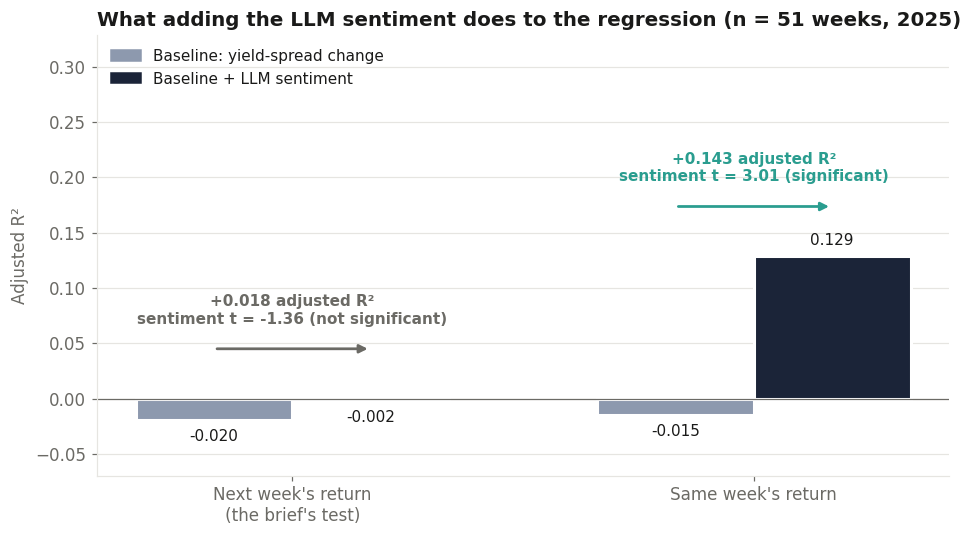

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
# ===== How much does sentiment add? Baseline vs baseline + sentiment (run after the regression cell) =====
import matplotlib.pyplot as plt

NAVY, UP_C, MUTED, INK, GRID = "#1B2438", "#2A9D8F", "#8D99AE", "#1a1a19", "#e6e5e1"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "text.color": INK, "axes.labelcolor": "#6b6a65",
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "axes.axisbelow": True, "xtick.color": "#6b6a65", "ytick.color": "#6b6a65", "axes.titleweight": "bold",
    "axes.titlesize": 13, "axes.titlelocation": "left", "figure.dpi": 110, "savefig.dpi": 220, "savefig.bbox": "tight"})

def fit(ycol, cols):
    y = s[ycol].values
    X = np.column_stack([np.ones(len(y))] + [s[c].values for c in cols])
    b = np.linalg.lstsq(X, y, rcond=None)[0]; e = y - X @ b; n_, k = X.shape
    se = np.sqrt(e @ e / (n_ - k) * np.diag(np.linalg.inv(X.T @ X)))
    r2 = 1 - e @ e / ((y - y.mean()) @ (y - y.mean()))
    return r2, 1 - (1 - r2) * (n_ - 1) / (n_ - k), b[-1] / se[-1]

cases = [("Next week's return\n(the brief's test)", "ret_next"), ("Same week's return", "ret")]
rows = []
for label, ycol in cases:
    r2_0, adj_0, _ = fit(ycol, ["dspread"])
    r2_1, adj_1, t_s = fit(ycol, ["dspread", "sentiment"])
    rows.append((label, adj_0, adj_1, t_s))

fig, ax = plt.subplots(figsize=(10, 5.2))
wbar, xs = 0.34, np.arange(len(rows))
for i, (label, a0, a1, t_s) in enumerate(rows):
    for dx, v, c in [(-wbar / 2, a0, MUTED), (wbar / 2, a1, NAVY)]:
        ax.bar(i + dx, v, width=wbar, color=c, edgecolor="white", linewidth=2)
        ax.text(i + dx, v + (0.008 if v >= 0 else -0.008), f"{v:.3f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=10)
    top = max(a0, a1, 0) + 0.06
    gain = a1 - a0
    sig = "significant" if abs(t_s) >= 1.96 else "not significant"
    c = UP_C if (gain > 0 and abs(t_s) >= 1.96) else "#6b6a65"          # teal only for a significant gain
    ax.annotate("", xy=(i + wbar / 2, top - 0.015), xytext=(i - wbar / 2, top - 0.015),
                arrowprops=dict(arrowstyle="-|>", color=c, lw=1.8))
    ax.text(i, top + 0.005, f"{gain:+.3f} adjusted R²\nsentiment t = {t_s:.2f} ({sig})", ha="center", va="bottom",
            fontsize=10, fontweight="bold", color=c)
ax.axhline(0, color="#6b6a65", lw=0.8)
ax.set_xticks(xs); ax.set_xticklabels([r[0] for r in rows]); ax.grid(axis="x", visible=False)
ax.set_ylabel("Adjusted R²")
lo = min(min(r[1], r[2]) for r in rows); hi = max(max(r[1], r[2]) for r in rows)
ax.set_ylim(min(lo - 0.05, -0.05), hi + 0.2)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=MUTED, label="Baseline: yield-spread change"),
                   plt.Rectangle((0, 0), 1, 1, color=NAVY, label="Baseline + LLM sentiment")],
          frameon=False, loc="upper left", fontsize=10)
ax.set_title(f"What adding the LLM sentiment does to the regression (n = {len(s)} weeks, 2025)")
fig.savefig("sentiment_improvement.png"); plt.show()
files.download("sentiment_improvement.png")

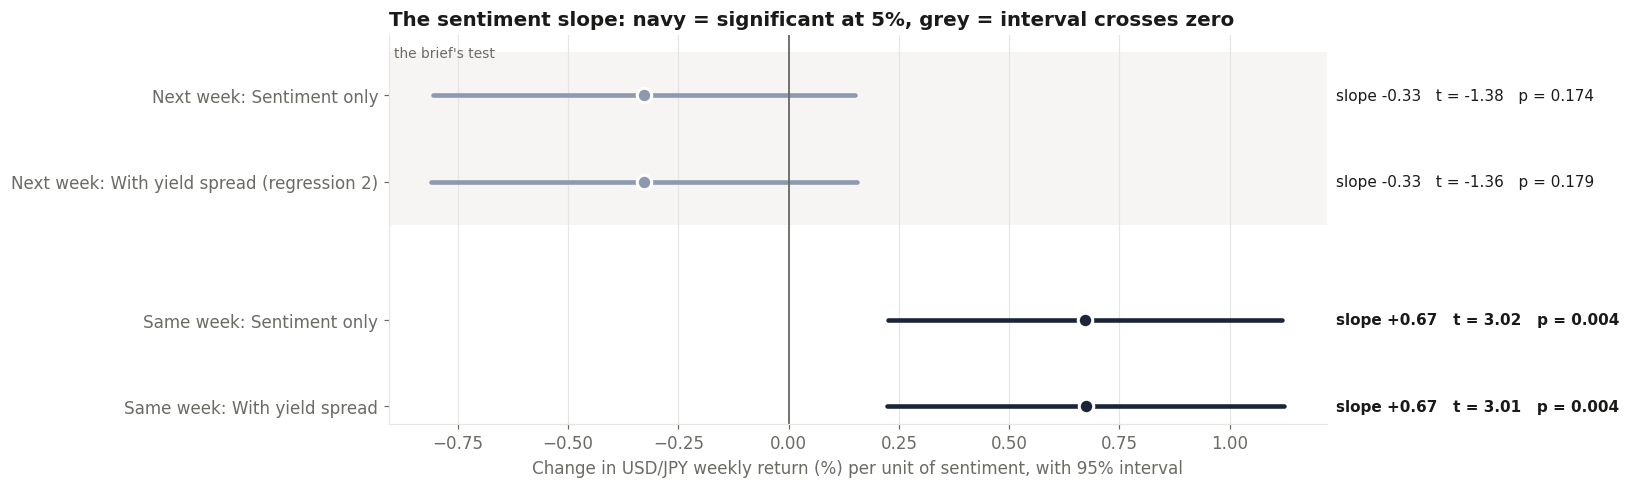

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
import matplotlib.pyplot as plt
from scipy import stats

NAVY, UP_C, MUTED, INK, GRID = "#1B2438", "#2A9D8F", "#8D99AE", "#1a1a19", "#e6e5e1"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "text.color": INK, "axes.labelcolor": "#6b6a65",
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "axes.axisbelow": True, "xtick.color": "#6b6a65", "ytick.color": "#6b6a65", "axes.titleweight": "bold",
    "axes.titlesize": 13, "axes.titlelocation": "left", "figure.dpi": 110, "savefig.dpi": 220, "savefig.bbox": "tight"})

def slope(ycol, cols):
    y = s[ycol].values
    X = np.column_stack([np.ones(len(y))] + [s[c].values for c in cols])
    b = np.linalg.lstsq(X, y, rcond=None)[0]; e = y - X @ b; n_, k = X.shape
    se = np.sqrt(e @ e / (n_ - k) * np.diag(np.linalg.inv(X.T @ X)))
    t = b[-1] / se[-1]; p = 2 * stats.t.sf(abs(t), n_ - k); crit = stats.t.ppf(0.975, n_ - k)
    return b[-1], b[-1] - crit * se[-1], b[-1] + crit * se[-1], t, p

specs = [("Next week", "Sentiment only", "ret_next", ["sentiment"]),
         ("Next week", "With yield spread (regression 2)", "ret_next", ["dspread", "sentiment"]),
         ("Same week", "Sentiment only", "ret", ["sentiment"]),
         ("Same week", "With yield spread", "ret", ["dspread", "sentiment"])]
fig, ax = plt.subplots(figsize=(11, 4.6))
ypos = [0, 1, 2.6, 3.6]
for yy, (grp, lab, ycol, cols) in zip(ypos, specs):
    b, lo, hi, t, p = slope(ycol, cols)
    sig = p < 0.05
    c = NAVY if sig else MUTED
    ax.plot([lo, hi], [yy, yy], color=c, lw=3, solid_capstyle="round")
    ax.scatter([b], [yy], s=90, color=c, edgecolor="white", linewidth=2, zorder=3)
    ptxt = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
    ax.text(1.01, yy, f"slope {b:+.2f}   t = {t:.2f}   {ptxt}", transform=ax.get_yaxis_transform(), va="center",
            fontsize=10, fontweight="bold" if sig else "normal", color=INK)
ax.axvline(0, color="#6b6a65", lw=1.2)
ax.set_yticks(ypos); ax.set_yticklabels([f"{g}: {l}" for g, l, *_ in specs]); ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.axhspan(-0.5, 1.5, color=GRID, alpha=0.35, lw=0)
ax.text(0.005, 0.97, "the brief's test", transform=ax.transAxes, fontsize=9, color="#6b6a65", va="top")
ax.set_xlabel("Change in USD/JPY weekly return (%) per unit of sentiment, with 95% interval")
ax.set_title("The sentiment slope: navy = significant at 5%, grey = interval crosses zero")
fig.savefig("sentiment_slope.png"); plt.show()
files.download("sentiment_slope.png")

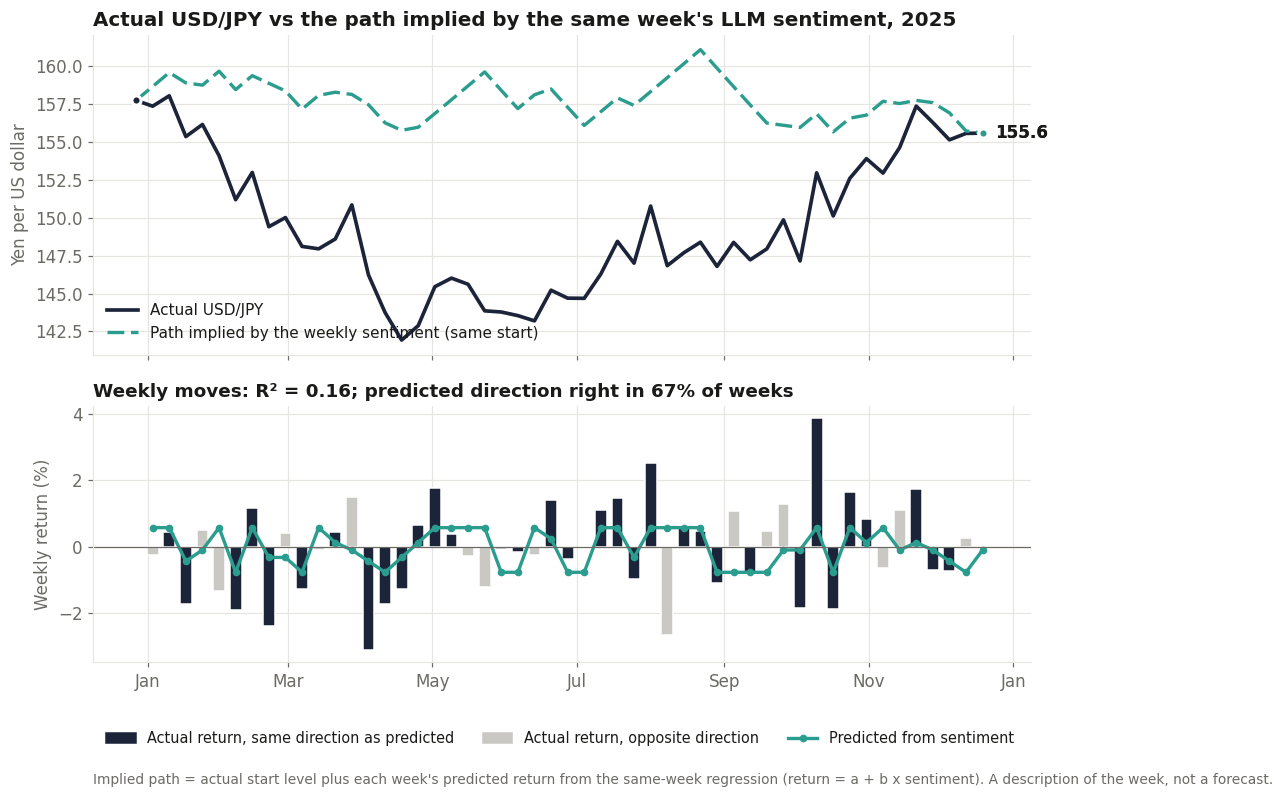

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
# ===== Actual USD/JPY moves vs the moves implied by the same week's sentiment =====
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.patches import Patch
from google.colab import files

NAVY, UP_C, DOWN_C, NEU_C = "#1B2438", "#2A9D8F", "#C8102E", "#8D99AE"
INK, MUTED, GRID = "#1a1a19", "#6b6a65", "#e6e5e1"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "text.color": INK, "axes.labelcolor": MUTED,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "figure.dpi": 110, "savefig.dpi": 220, "savefig.bbox": "tight"})

d = w[(w.week >= "2025-01-03") & (w.week <= "2025-12-19")].dropna(subset=["ret", "sentiment"]).copy()
X = np.column_stack([np.ones(len(d)), d.sentiment.values])
b = np.linalg.lstsq(X, d.ret.values, rcond=None)[0]            # same-week regression: return = a + b * sentiment
d["pred"] = X @ b
r2 = 1 - ((d.ret - d.pred) ** 2).sum() / ((d.ret - d.ret.mean()) ** 2).sum()
hit = (np.sign(d.ret) == np.sign(d.pred)).mean()

# implied USD/JPY level: start at the actual level, then add the predicted weekly returns
start_row = w.loc[w.week < d.week.iloc[0]].iloc[-1]
start = start_row.usdjpy
d["implied"] = start * np.exp(d.pred.cumsum() / 100)
path = pd.concat([pd.DataFrame({"week": [start_row.week], "usdjpy": [start], "implied": [start]}), d[["week", "usdjpy", "implied"]]])

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 7.4), sharex=True, gridspec_kw={"height_ratios": [1.25, 1], "hspace": 0.18})

# top: actual vs sentiment-implied path
a1.plot(path.week, path.usdjpy, color=NAVY, lw=2.4, label="Actual USD/JPY")
a1.plot(path.week, path.implied, color=UP_C, lw=2.2, ls=(0, (5, 2)), label="Path implied by the weekly sentiment (same start)")
a1.scatter([path.week.iloc[0]], [start], color=NAVY, s=36, zorder=3, edgecolor="white", linewidth=2)
for col, c in [("usdjpy", NAVY), ("implied", UP_C)]:
    a1.scatter([d.week.iloc[-1]], [d[col].iloc[-1]], color=c, s=36, zorder=3, edgecolor="white", linewidth=2)
    a1.annotate(f"{d[col].iloc[-1]:.1f}", (d.week.iloc[-1], d[col].iloc[-1]), xytext=(8, 0), textcoords="offset points", va="center", fontweight="bold")
a1.set_ylabel("Yen per US dollar"); a1.margins(x=0.04)
a1.legend(frameon=False, loc="lower left", fontsize=10)
a1.set_title("Actual USD/JPY vs the path implied by the same week's LLM sentiment, 2025")

# bottom: weekly actual return vs predicted
cols = np.where(np.sign(d.ret) == np.sign(d.pred), NAVY, "#c9c8c2")
a2.bar(d.week, d.ret, width=5, color=cols, edgecolor="white", linewidth=1)
a2.plot(d.week, d.pred, color=UP_C, lw=2.2, marker="o", markersize=4)
a2.axhline(0, color=MUTED, lw=0.8)
a2.set_ylabel("Weekly return (%)"); a2.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
a2.legend(handles=[Patch(color=NAVY, label="Actual return, same direction as predicted"),
                   Patch(color="#c9c8c2", label="Actual return, opposite direction"),
                   plt.Line2D([], [], color=UP_C, lw=2.2, marker="o", markersize=4, label="Predicted from sentiment")],
          frameon=False, ncol=3, loc="lower left", bbox_to_anchor=(0, -0.38), fontsize=9.5)
a2.set_title(f"Weekly moves: R² = {r2:.2f}; predicted direction right in {hit:.0%} of weeks", fontsize=12)

fig.text(0.125, -0.04, "Implied path = actual start level plus each week's predicted return from the same-week regression "
         "(return = a + b x sentiment). A description of the week, not a forecast.", fontsize=9, color=MUTED)
fig.savefig("best5_actual_vs_predicted.png"); plt.show()
files.download("best5_actual_vs_predicted.png")

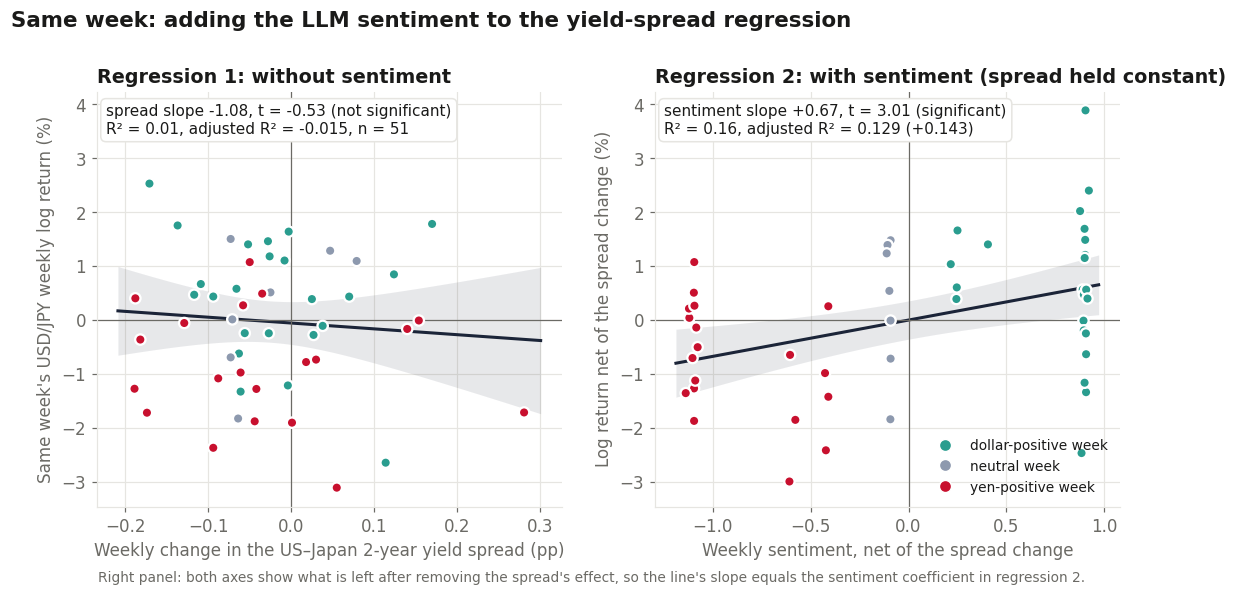

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
# ===== Same week: regression without vs with sentiment (run after the regression cell) =====
import numpy as np, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats

NAVY, UP_C, DOWN_C, NEU_C = "#1B2438", "#2A9D8F", "#C8102E", "#8D99AE"
INK, MUTED, GRID = "#1a1a19", "#6b6a65", "#e6e5e1"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "text.color": INK, "axes.labelcolor": MUTED,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED, "axes.titleweight": "bold", "axes.titlesize": 12.5,
    "axes.titlelocation": "left", "figure.dpi": 110, "savefig.dpi": 220, "savefig.bbox": "tight"})

y = s.ret.values                                    # same-week USD/JPY weekly log return (%)
sp, se_ = s.dspread.values, s.sentiment.values
pc = np.where(se_ > 0, UP_C, np.where(se_ < 0, DOWN_C, NEU_C))
KEY = [Line2D([], [], marker="o", ls="", color=c, markeredgecolor="white", markersize=8, label=l)
       for c, l in [(UP_C, "dollar-positive week"), (NEU_C, "neutral week"), (DOWN_C, "yen-positive week")]]

def ols(y, cols):
    X = np.column_stack([np.ones(len(y))] + cols); b = np.linalg.lstsq(X, y, rcond=None)[0]
    e = y - X @ b; n, k = X.shape; cov = e @ e / (n - k) * np.linalg.inv(X.T @ X); se = np.sqrt(np.diag(cov))
    r2 = 1 - e @ e / ((y - y.mean()) @ (y - y.mean()))
    return b, se, r2, 1 - (1 - r2) * (n - 1) / (n - k), n, cov

b1, s1, r2_1, adj1, n, cov1 = ols(y, [sp])            # regression 1: return on spread change
b2, s2, r2_2, adj2, _, _ = ols(y, [sp, se_])          # regression 2: + sentiment
p = lambda b, s_, k: 2 * stats.t.sf(abs(b / s_), n - k)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(12, 4.9), sharey=True)

# left: regression 1 (without sentiment)
xs = np.linspace(sp.min() - 0.02, sp.max() + 0.02, 60); Xs = np.column_stack([np.ones_like(xs), xs])
band = 1.96 * np.sqrt(np.einsum("ij,jk,ik->i", Xs, cov1, Xs))
axL.fill_between(xs, Xs @ b1 - band, Xs @ b1 + band, color=NAVY, alpha=0.10, lw=0)
axL.plot(xs, Xs @ b1, color=NAVY, lw=2)
axL.scatter(sp, y, s=46, c=pc, edgecolor="white", linewidth=1.5, zorder=3)
axL.axhline(0, color=MUTED, lw=0.8); axL.axvline(0, color=MUTED, lw=0.8)
sig1 = "significant" if p(b1[1], s1[1], 2) < 0.05 else "not significant"
axL.text(0.02, 0.97, f"spread slope {b1[1]:+.2f}, t = {b1[1] / s1[1]:.2f} ({sig1})\nR² = {r2_1:.2f}, adjusted R² = {adj1:.3f}, n = {n}",
         transform=axL.transAxes, va="top", fontsize=10, bbox=dict(boxstyle="round,pad=0.35", fc="white", ec=GRID))
axL.set_xlabel("Weekly change in the US–Japan 2-year yield spread (pp)")
axL.set_ylabel("Same week's USD/JPY weekly log return (%)")
axL.set_title("Regression 1: without sentiment")

# right: regression 2 (with sentiment) - the sentiment effect once the spread is accounted for
def resid(v): Z = np.column_stack([np.ones(len(sp)), sp]); return v - Z @ np.linalg.lstsq(Z, v, rcond=None)[0]
ry, rx = resid(y), resid(se_)
xs = np.linspace(rx.min() - 0.05, rx.max() + 0.05, 60)
bb = np.linalg.lstsq(np.column_stack([np.ones(len(rx)), rx]), ry, rcond=None)[0]
e = ry - (bb[0] + bb[1] * rx); covb = e @ e / (n - 3) * np.linalg.inv(np.column_stack([np.ones(len(rx)), rx]).T @ np.column_stack([np.ones(len(rx)), rx]))
Xs = np.column_stack([np.ones_like(xs), xs]); band = 1.96 * np.sqrt(np.einsum("ij,jk,ik->i", Xs, covb, Xs))
axR.fill_between(xs, Xs @ bb - band, Xs @ bb + band, color=NAVY, alpha=0.10, lw=0)
axR.plot(xs, Xs @ bb, color=NAVY, lw=2)
axR.scatter(rx, ry, s=46, c=pc, edgecolor="white", linewidth=1.5, zorder=3)
axR.axhline(0, color=MUTED, lw=0.8); axR.axvline(0, color=MUTED, lw=0.8)
sig2 = "significant" if p(b2[2], s2[2], 3) < 0.05 else "not significant"
axR.text(0.02, 0.97, f"sentiment slope {b2[2]:+.2f}, t = {b2[2] / s2[2]:.2f} ({sig2})\nR² = {r2_2:.2f}, adjusted R² = {adj2:.3f} ({adj2 - adj1:+.3f})",
         transform=axR.transAxes, va="top", fontsize=10, bbox=dict(boxstyle="round,pad=0.35", fc="white", ec=GRID))
axR.legend(handles=KEY, frameon=False, fontsize=9, loc="lower right")
axR.set_xlabel("Weekly sentiment, net of the spread change")
axR.set_ylabel("Log return net of the spread change (%)"); axR.yaxis.set_tick_params(labelleft=True)
axR.set_title("Regression 2: with sentiment (spread held constant)")

fig.suptitle("Same week: adding the LLM sentiment to the yield-spread regression", x=0.06, ha="left", fontsize=14, fontweight="bold", y=1.03)
fig.text(0.5, -0.03, "Right panel: both axes show what is left after removing the spread's effect, so the line's slope equals the sentiment coefficient in regression 2.",
         ha="center", fontsize=9, color=MUTED)
fig.savefig("same_week_regressions.png"); plt.show()
files.download("same_week_regressions.png")

## 10. Look-ahead check: before vs after the model's training cutoff
Following Lopez-Lira & Tang (Online Appendix C): if the model had memorised what happened, its scores would work better on articles it may have seen in training than on articles published after its cutoff.

In [25]:
import numpy as np
from openpyxl import load_workbook
# weekly USD/JPY returns from the model's Daily sheet (Friday closes)
ws = load_workbook(MODEL_IN, read_only=True)['Daily']
px = pd.DataFrame([(r[0], r[1]) for r in ws.iter_rows(min_row=2, max_col=2, values_only=True) if r[0] and r[1]],
                  columns=['date', 'usdjpy'])
px['date'] = pd.to_datetime(px['date'])
fri = px.set_index('date')['usdjpy'].resample('W-FRI').last().dropna()
ret = np.log(fri).diff()
# weekly sentiment, same rule as the model: mean of +1/0/-1 per Saturday-Friday week, 0 if no article
num = res.tone.map({'UP': 1, 'DOWN': -1, 'UNCERTAIN': 0})
wk = pd.to_datetime(res.date) + pd.to_timedelta((4 - pd.to_datetime(res.date).dt.weekday) % 7, unit='D')
score = num.groupby(wk.values).mean()
weeks = pd.date_range('2025-01-03', '2025-12-26', freq='W-FRI')
d = pd.DataFrame({'sent': score.reindex(weeks).fillna(0), 'ret_next': ret.shift(-1).reindex(weeks)}).dropna()

def ols(x, y):
    X = np.column_stack([np.ones(len(x)), x]); b = np.linalg.lstsq(X, y, rcond=None)[0]
    e = y - X @ b; s2 = e @ e / (len(y) - 2); se = np.sqrt(s2 * np.linalg.inv(X.T @ X)[1, 1])
    return b[1], b[1] / se, len(y)

cut = pd.Timestamp(TRAINING_CUTOFF)
rows = []
for name, part in [('Whole 2025', d), (f'Before cutoff (to {cut:%d %b})', d[d.index <= cut]), (f'After cutoff (from {cut:%d %b})', d[d.index > cut])]:
    slope, t, n = ols(part.sent.values, part.ret_next.values)
    rows.append({'Period': name, 'Weeks': n, 'Slope': round(slope, 5), 't-stat': round(t, 2)})
check = pd.DataFrame(rows)
print('Next-week USD/JPY return on weekly sentiment')
print(check.to_string(index=False))
print('\nIf the slope has the same sign and a similar size after the cutoff, look-ahead bias is unlikely to drive the result.'
      '\nThe after-cutoff period is short, so treat it as a robustness check, not a separate test.')
check.to_csv('lookahead_check.csv', index=False)
files.download('lookahead_check.csv')

Next-week USD/JPY return on weekly sentiment
                    Period  Weeks    Slope  t-stat
                Whole 2025     51 -0.00328   -1.38
 Before cutoff (to 31 May)     22 -0.00194   -0.54
After cutoff (from 31 May)     29 -0.00368   -1.19

If the slope has the same sign and a similar size after the cutoff, look-ahead bias is unlikely to drive the result.
The after-cutoff period is short, so treat it as a robustness check, not a separate test.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Plots and figures for the presentation

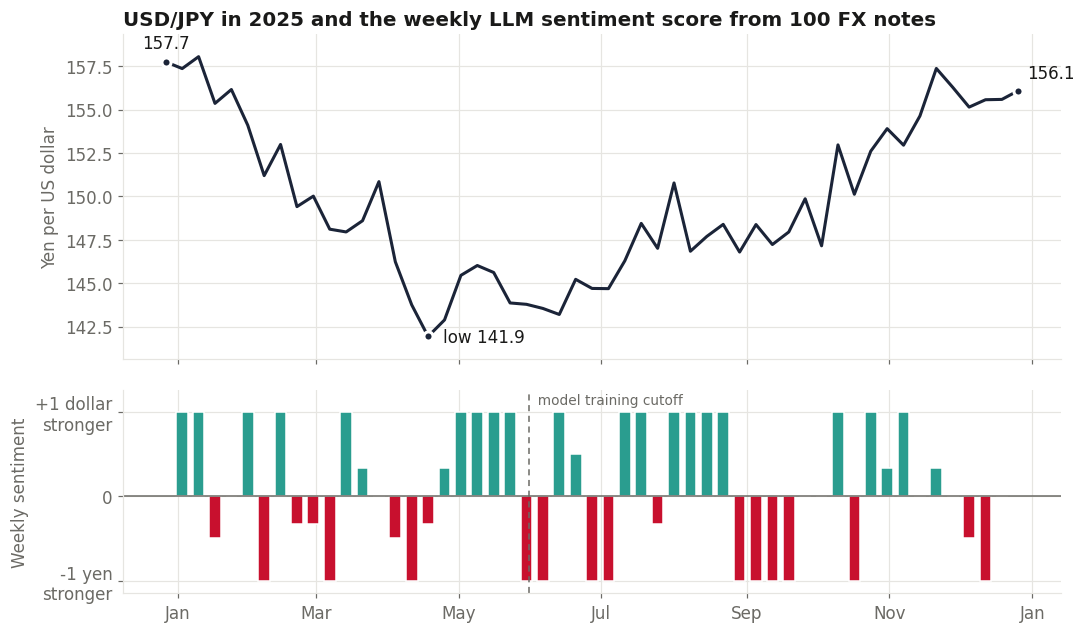

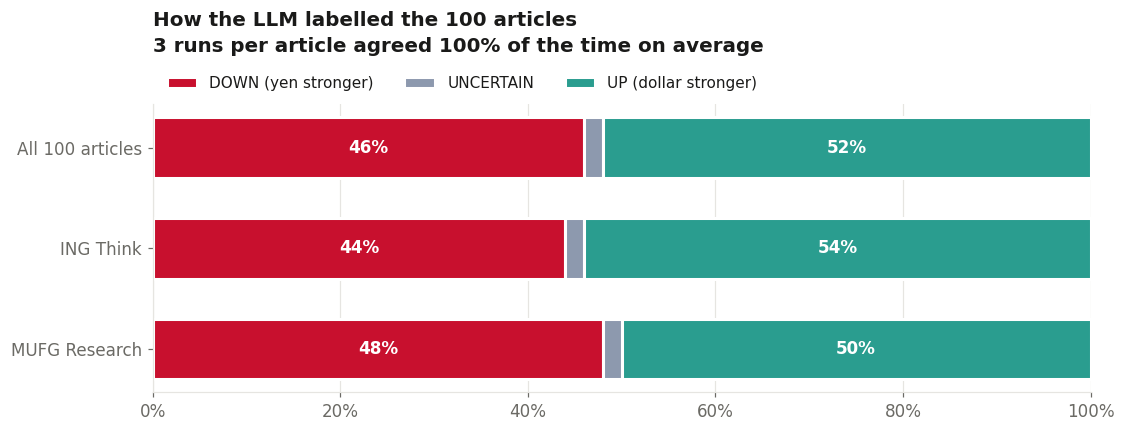

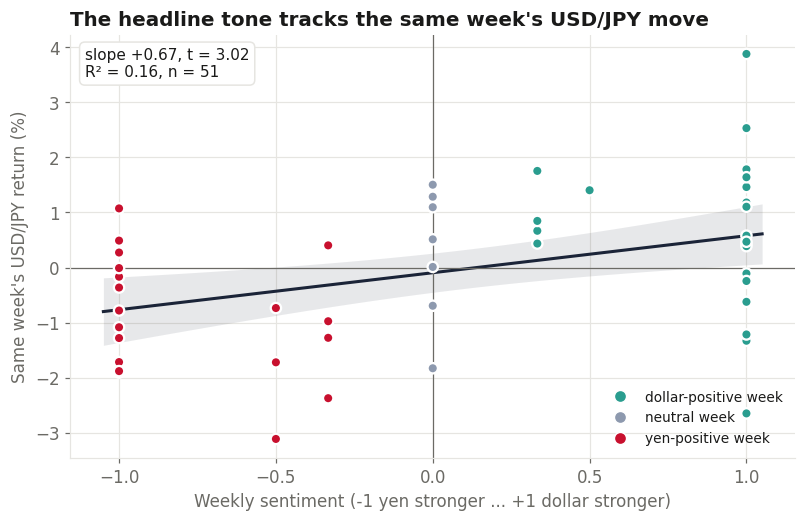

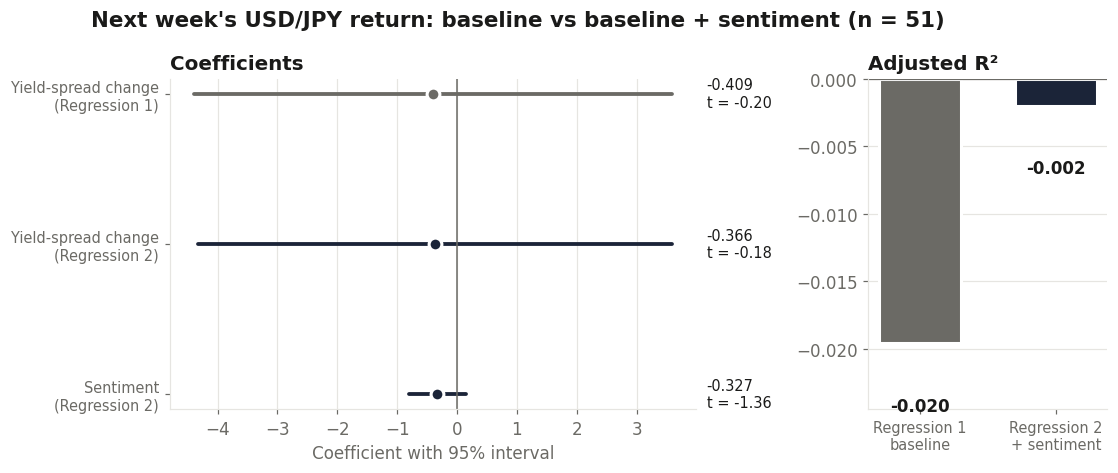

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.lines import Line2D
from google.colab import files

NAVY, UP_C, DOWN_C, NEU_C = "#1B2438", "#2A9D8F", "#C8102E", "#8D99AE"   # deck colours
INK, MUTED, GRID = "#1a1a19", "#6b6a65", "#e6e5e1"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "text.color": INK, "axes.labelcolor": MUTED,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "figure.dpi": 110, "savefig.dpi": 220, "savefig.bbox": "tight"})
CUT = pd.Timestamp(globals().get("TRAINING_CUTOFF", "2025-05-31"))
d = w[(w.week >= "2025-01-03") & (w.week <= "2025-12-19")].dropna(subset=["ret", "ret_next", "dspread", "sentiment"]).copy()
colour = lambda s: np.where(s > 0, UP_C, np.where(s < 0, DOWN_C, NEU_C))
KEY = [Line2D([], [], marker="o", ls="", color=c, markeredgecolor="white", markersize=8, label=l)
       for c, l in [(UP_C, "dollar-positive week"), (NEU_C, "neutral week"), (DOWN_C, "yen-positive week")]]

def ols(y, X):
    X = np.column_stack([np.ones(len(y))] + X); b = np.linalg.lstsq(X, y, rcond=None)[0]
    e = y - X @ b; n, k = X.shape; cov = e @ e / (n - k) * np.linalg.inv(X.T @ X)
    r2 = 1 - e @ e / ((y - y.mean()) @ (y - y.mean()))
    return b, np.sqrt(np.diag(cov)), r2, 1 - (1 - r2) * (n - 1) / (n - k), n, cov
out = []

# 1. USD/JPY and the weekly sentiment (one time axis, two panels)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6.6), sharex=True, gridspec_kw={"height_ratios": [1.6, 1], "hspace": 0.12})
p = w[(w.week >= "2024-12-27") & (w.week <= "2025-12-26")]
a1.plot(p.week, p.usdjpy, color=NAVY, lw=2)
lo = p.loc[p.usdjpy.idxmin()]
for (x, y), txt, off in [((p.week.iloc[0], p.usdjpy.iloc[0]), f"{p.usdjpy.iloc[0]:.1f}", (0, 9)),
                         ((p.week.iloc[-1], p.usdjpy.iloc[-1]), f"{p.usdjpy.iloc[-1]:.1f}", (6, 8)),
                         ((lo.week, lo.usdjpy), f"low {lo.usdjpy:.1f}", (10, -4))]:
    a1.scatter([x], [y], color=NAVY, s=36, zorder=3, edgecolor="white", linewidth=2)
    a1.annotate(txt, (x, y), xytext=off, textcoords="offset points", ha="center" if off[0] == 0 else "left")
a1.set_ylabel("Yen per US dollar"); a1.margins(x=0.03, y=0.08)
a1.set_title("USD/JPY in 2025 and the weekly LLM sentiment score from 100 FX notes")
a2.bar(d.week, d.sentiment, width=5, color=colour(d.sentiment), edgecolor="white", linewidth=1)
a2.axhline(0, color=MUTED, lw=1); a2.axvline(CUT, color=MUTED, lw=1, ls=(0, (4, 3)))
a2.text(CUT, 1.05, "  model training cutoff", color=MUTED, fontsize=9, va="bottom")
a2.set_ylim(-1.15, 1.25); a2.set_yticks([-1, 0, 1]); a2.set_yticklabels(["-1 yen\nstronger", "0", "+1 dollar\nstronger"])
a2.set_ylabel("Weekly sentiment"); a2.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.savefig("best1_usdjpy_sentiment.png"); out.append("best1_usdjpy_sentiment.png"); plt.show()

# 2. Label mix by source
src = res.source.astype(str).str.contains("MUFG", case=False).map({True: "MUFG Research", False: "ING Think"})
order = ["DOWN", "UNCERTAIN", "UP"]
mix = pd.crosstab(src, res.tone, normalize="index").reindex(columns=order, fill_value=0)
mix.loc["All 100 articles"] = res.tone.value_counts(normalize=True).reindex(order, fill_value=0)
mix = mix.loc[["All 100 articles", "ING Think", "MUFG Research"]]
fig, ax = plt.subplots(figsize=(11, 3.4)); left = np.zeros(len(mix))
for lab, c, name in [("DOWN", DOWN_C, "DOWN (yen stronger)"), ("UNCERTAIN", NEU_C, "UNCERTAIN"), ("UP", UP_C, "UP (dollar stronger)")]:
    v = mix[lab].values
    ax.barh(mix.index, v, left=left, color=c, edgecolor="white", linewidth=2, height=0.6, label=name)
    for i, x in enumerate(v):
        if x >= 0.06: ax.text(left[i] + x / 2, i, f"{x:.0%}", ha="center", va="center", color="white", fontweight="bold")
    left += v
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.grid(axis="y", visible=False)
ax.legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False, fontsize=10)
agree = f"\n3 runs per article agreed {res.tone_agree.mean():.0%} of the time on average" if "tone_agree" in res else ""
ax.set_title(f"How the LLM labelled the 100 articles{agree}", pad=34, linespacing=1.5)
fig.savefig("best2_label_mix.png"); out.append("best2_label_mix.png"); plt.show()

# 3. Same week: the tone tracks the week's move
y, x = d.ret.values, d.sentiment.values
b, se, r2, _, n, cov = ols(y, [x])
fig, ax = plt.subplots(figsize=(8.5, 5))
xs = np.linspace(-1.05, 1.05, 50); Xs = np.column_stack([np.ones_like(xs), xs]); band = 1.96 * np.sqrt(np.einsum("ij,jk,ik->i", Xs, cov, Xs))
ax.fill_between(xs, Xs @ b - band, Xs @ b + band, color=NAVY, alpha=0.10, lw=0); ax.plot(xs, Xs @ b, color=NAVY, lw=2)
ax.scatter(x, y, s=46, c=colour(x), edgecolor="white", linewidth=1.5, zorder=3)
ax.axhline(0, color=MUTED, lw=0.8); ax.axvline(0, color=MUTED, lw=0.8)
ax.text(0.02, 0.97, f"slope {b[1]:+.2f}, t = {b[1] / se[1]:.2f}\nR² = {r2:.2f}, n = {n}", transform=ax.transAxes, va="top", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.35", fc="white", ec=GRID))
ax.legend(handles=KEY, frameon=False, fontsize=9, loc="lower right")
ax.set_xlabel("Weekly sentiment (-1 yen stronger ... +1 dollar stronger)"); ax.set_ylabel("Same week's USD/JPY return (%)")
ax.set_title("The headline tone tracks the same week's USD/JPY move")
fig.savefig("best3_same_week.png"); out.append("best3_same_week.png"); plt.show()

# 4. Step 4 of the brief: regression 1 (baseline) vs regression 2 (+ sentiment), Y = next-week return
y = d.ret_next.values
b1, se1, r2_1, adj1, n, _ = ols(y, [d.dspread.values])
b2, se2, r2_2, adj2, _, _ = ols(y, [d.dspread.values, d.sentiment.values])
fig, (axc, axr) = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={"width_ratios": [2.2, 1], "wspace": 0.45})
items = [("Yield-spread change\n(Regression 1)", b1[1], se1[1], MUTED), ("Yield-spread change\n(Regression 2)", b2[1], se2[1], NAVY),
         ("Sentiment\n(Regression 2)", b2[2], se2[2], NAVY)]
for i, (lab, bb, ss, c) in enumerate(items):
    axc.plot([bb - 1.96 * ss, bb + 1.96 * ss], [i, i], color=c, lw=2.5, solid_capstyle="round")
    axc.scatter([bb], [i], s=70, color=c, edgecolor="white", linewidth=2, zorder=3)
    axc.text(1.02, i, f"{bb:+.3f}\nt = {bb / ss:.2f}", transform=axc.get_yaxis_transform(), va="center", fontsize=9.5)
axc.axvline(0, color=MUTED, lw=1); axc.set_yticks(range(3)); axc.set_yticklabels([i[0] for i in items], fontsize=9.5)
axc.invert_yaxis(); axc.grid(axis="y", visible=False); axc.set_xlabel("Coefficient with 95% interval"); axc.set_title("Coefficients")
axr.bar([0, 1], [adj1, adj2], color=[MUTED, NAVY], width=0.6, edgecolor="white", linewidth=2)
for i, v in enumerate([adj1, adj2]):
    axr.text(i, v + (0.004 if v >= 0 else -0.004), f"{v:.3f}", ha="center", va="bottom" if v >= 0 else "top", fontweight="bold")
axr.axhline(0, color=MUTED, lw=0.8); axr.set_xticks([0, 1]); axr.set_xticklabels(["Regression 1\nbaseline", "Regression 2\n+ sentiment"], fontsize=9.5)
axr.grid(axis="x", visible=False); axr.margins(y=0.25); axr.set_title("Adjusted R²")
fig.suptitle(f"Next week's USD/JPY return: baseline vs baseline + sentiment (n = {n})", x=0.06, ha="left", fontsize=14, fontweight="bold", y=1.04)
fig.savefig("best4_regressions.png"); out.append("best4_regressions.png"); plt.show()

for f in out: files.download(f)